# Air Quality Scenarios in Mexico City (2025): Clustering and Profiling

**Goal.** Characterize how air quality behaves in Mexico City during 2025 by grouping every
station-hour into a small number of *atmospheric scenarios* and profiling when and where
each scenario happens.

**Data.** Hourly concentrations of 9 pollutants published by Mexico City's Environment
Department (SEDEMA), one file per pollutant. See `data/README.md` for how to download them.

**Outline**
1. Load and merge the pollutant files
2. Data quality: missing values, station selection, outliers, imputation
3. Exploratory analysis
4. Choosing the number of clusters
5. K-Means clustering
6. Scenario profiling: by hour, weekday, month and station
7. Conclusions

This notebook is the first part of the project. The second part
(`02_lstm_forecasting_2020_2025.ipynb`) extends the data to 2020–2025 and trains an LSTM that
forecasts the scenario of the next hour.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.preprocessing import MinMaxScaler, StandardScaler

from cdmx_air import cleaning, clustering
from cdmx_air.clustering import SCENARIO_ORDER
from cdmx_air.config import MODEL_FEATURES, POLLUTANTS, SELECTED_STATIONS
from cdmx_air.data import add_calendar_features, load_years
from cdmx_air.plots import SCENARIO_COLORS, missing_heatmap, save_fig, set_style, stacked_share

warnings.filterwarnings("ignore", category=FutureWarning)
# MICE stops at max_iter=10 before its tolerance is met; the imputed values are stable enough.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
set_style()
pd.set_option("display.precision", 2)
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

## 1. Load and merge the pollutant files

Each SEDEMA file has one row per hour and one column per monitoring station. The files are
reshaped to long format (one row per station-hour) and merged on `datetime` and `station`.
SEDEMA marks missing readings with `-99`, which are converted to `NaN` while loading.

In [2]:
raw = load_years([2025])
print(f"{len(raw):,} station-hours, {raw['station'].nunique()} stations")
raw.head()

315,360 station-hours, 36 stations


,datetime,station,CO,NO,NO2,NOX,O3,PM10,PM25,PMCO,SO2
0,2025-01-01 01:00:00,ACO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2025-01-01 02:00:00,ACO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2025-01-01 03:00:00,ACO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2025-01-01 04:00:00,ACO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2025-01-01 05:00:00,ACO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data quality

In [3]:
cleaning.quality_report(raw)

,dtype,missing,missing_pct
PMCO,float64,250666,79.49
PM25,float64,214375,67.98
PM10,float64,187447,59.44
NOX,float64,150862,47.84
NO,float64,150861,47.84
NO2,float64,126427,40.09
SO2,float64,124368,39.44
CO,float64,119637,37.94
O3,float64,96537,30.61
station,str,0,0.00


There are many missing values, especially in **PM10**, **PM2.5** and **PMCO**. PM10 and PM2.5
are key to air quality, so instead of dropping them we look at where the gaps are.
**PMCO** is dropped: it is the coarse fraction (PM10 − PM2.5), so it adds no new information.

### 2.1 Missing data by station

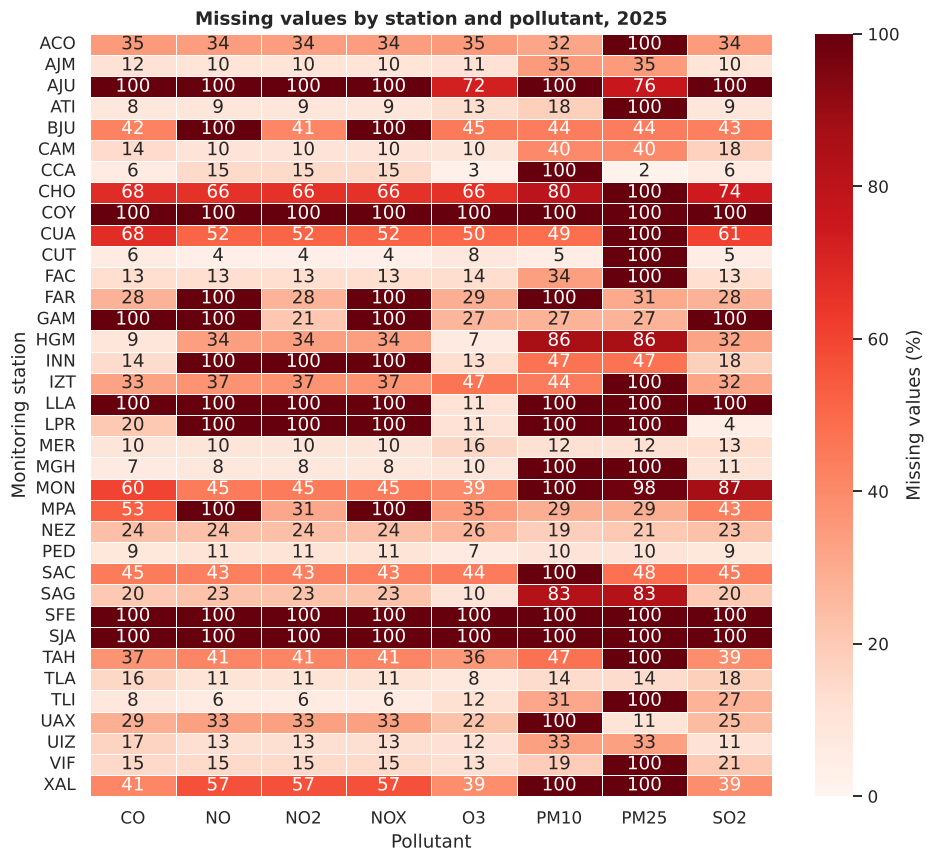

In [4]:
fig = missing_heatmap(
    cleaning.missing_by_station(raw, POLLUTANTS), "Missing values by station and pollutant, 2025"
)
save_fig(fig, "01_missing_by_station")
plt.show()

Many stations either do not measure some pollutants at all (100% missing) or have large gaps.
The only stations that measure **every** pollutant with an acceptable share of missing data are
**AJM, CAM, MER, NEZ, PED, TLA and UIZ**, so the analysis keeps those seven.

In [5]:
df = raw.loc[raw["station"].isin(SELECTED_STATIONS)].drop(columns="PMCO")
print(f"{len(df):,} station-hours after keeping {len(SELECTED_STATIONS)} stations")
cleaning.quality_report(df[POLLUTANTS])

61,320 station-hours after keeping 7 stations


,dtype,missing,missing_pct
PM25,float64,14497,23.64
PM10,float64,14308,23.33
SO2,float64,8950,14.60
CO,float64,8826,14.39
O3,float64,7853,12.81
NOX,float64,7688,12.54
NO,float64,7688,12.54
NO2,float64,7688,12.54


### 2.2 Outliers

Outliers are flagged with the IQR rule (above Q3 + 1.5 × IQR).

In [6]:
cleaning.outlier_report(df, POLLUTANTS)

,q1,q3,upper_fence,max,outliers,outliers_pct
NO,1.00,12.00,28.50,381.00,6199,10.11
SO2,1.00,3.00,6.00,164.00,4868,7.94
NOX,17.00,45.00,87.00,447.00,3478,5.67
CO,0.26,0.63,1.18,4.71,2814,4.59
NO2,15.00,32.00,57.50,115.00,1148,1.87
PM25,12.00,27.00,49.50,268.00,949,1.55
PM10,22.00,48.00,87.00,332.00,941,1.53
O3,9.00,51.00,114.00,168.00,650,1.06


The outliers are kept: they are real, expected readings from days with very poor air quality,
and those are exactly the days we do not want to lose. Instead, they are **capped** at the
upper fence. A capped hour still stands out as "higher than normal", but extreme values no
longer distort the imputation and the distance-based clustering.

In [7]:
upper_bounds = cleaning.iqr_upper_bounds(df, POLLUTANTS)
df = cleaning.cap_outliers(df, upper_bounds)
pd.DataFrame({"upper_bound": upper_bounds})

,upper_bound
CO,1.19
NO,28.50
NO2,57.50
NOX,87.00
O3,114.00
PM10,87.00
PM25,49.50
SO2,6.00


### 2.3 Missing value imputation

Two complementary methods are used:

1. **Linear interpolation** for short gaps (up to 3 consecutive hours) within each station's
   own series. Concentrations should not change much over a few hours.
2. **MICE** (Multivariate Imputation by Chained Equations, scikit-learn's `IterativeImputer`)
   for longer gaps. It estimates each pollutant from the others, using the strong chemical
   relationships between them.

In [8]:
missing_before = df[POLLUTANTS].isna().sum().sum()
df = cleaning.interpolate_short_gaps(df, POLLUTANTS, limit=3)
missing_after_interp = df[POLLUTANTS].isna().sum().sum()

imputer = cleaning.fit_imputer(df, POLLUTANTS)
df = cleaning.apply_imputer(df, POLLUTANTS, imputer)

print(f"Missing values before:             {missing_before:,}")
print(f"Filled by interpolation:           {missing_before - missing_after_interp:,}")
print(f"Filled by MICE:                    {missing_after_interp:,}")
print(f"Missing values after imputation:   {df[POLLUTANTS].isna().sum().sum()}")

Missing values before:             77,498
Filled by interpolation:           11,797
Filled by MICE:                    65,701
Missing values after imputation:   0


## 3. Exploratory analysis

In [9]:
df[POLLUTANTS].describe().T

,count,mean,std,min,25%,50%,75%,max
CO,61320.0,0.48,0.28,0.0,0.27,0.43,0.6,1.19
NO,61320.0,8.12,9.01,0.0,1.00,4.00,10.8,28.50
NO2,61320.0,24.36,11.95,0.0,16.00,23.01,31.0,57.50
NOX,61320.0,33.87,21.48,1.0,18.00,29.26,43.0,87.00
O3,61320.0,32.53,27.52,0.0,10.00,26.45,47.0,114.00
PM10,61320.0,35.62,17.40,1.0,23.00,34.00,45.0,87.00
PM25,61320.0,19.82,10.21,1.0,12.00,19.00,25.0,49.50
SO2,61320.0,2.23,1.66,0.0,1.00,2.00,3.0,6.00


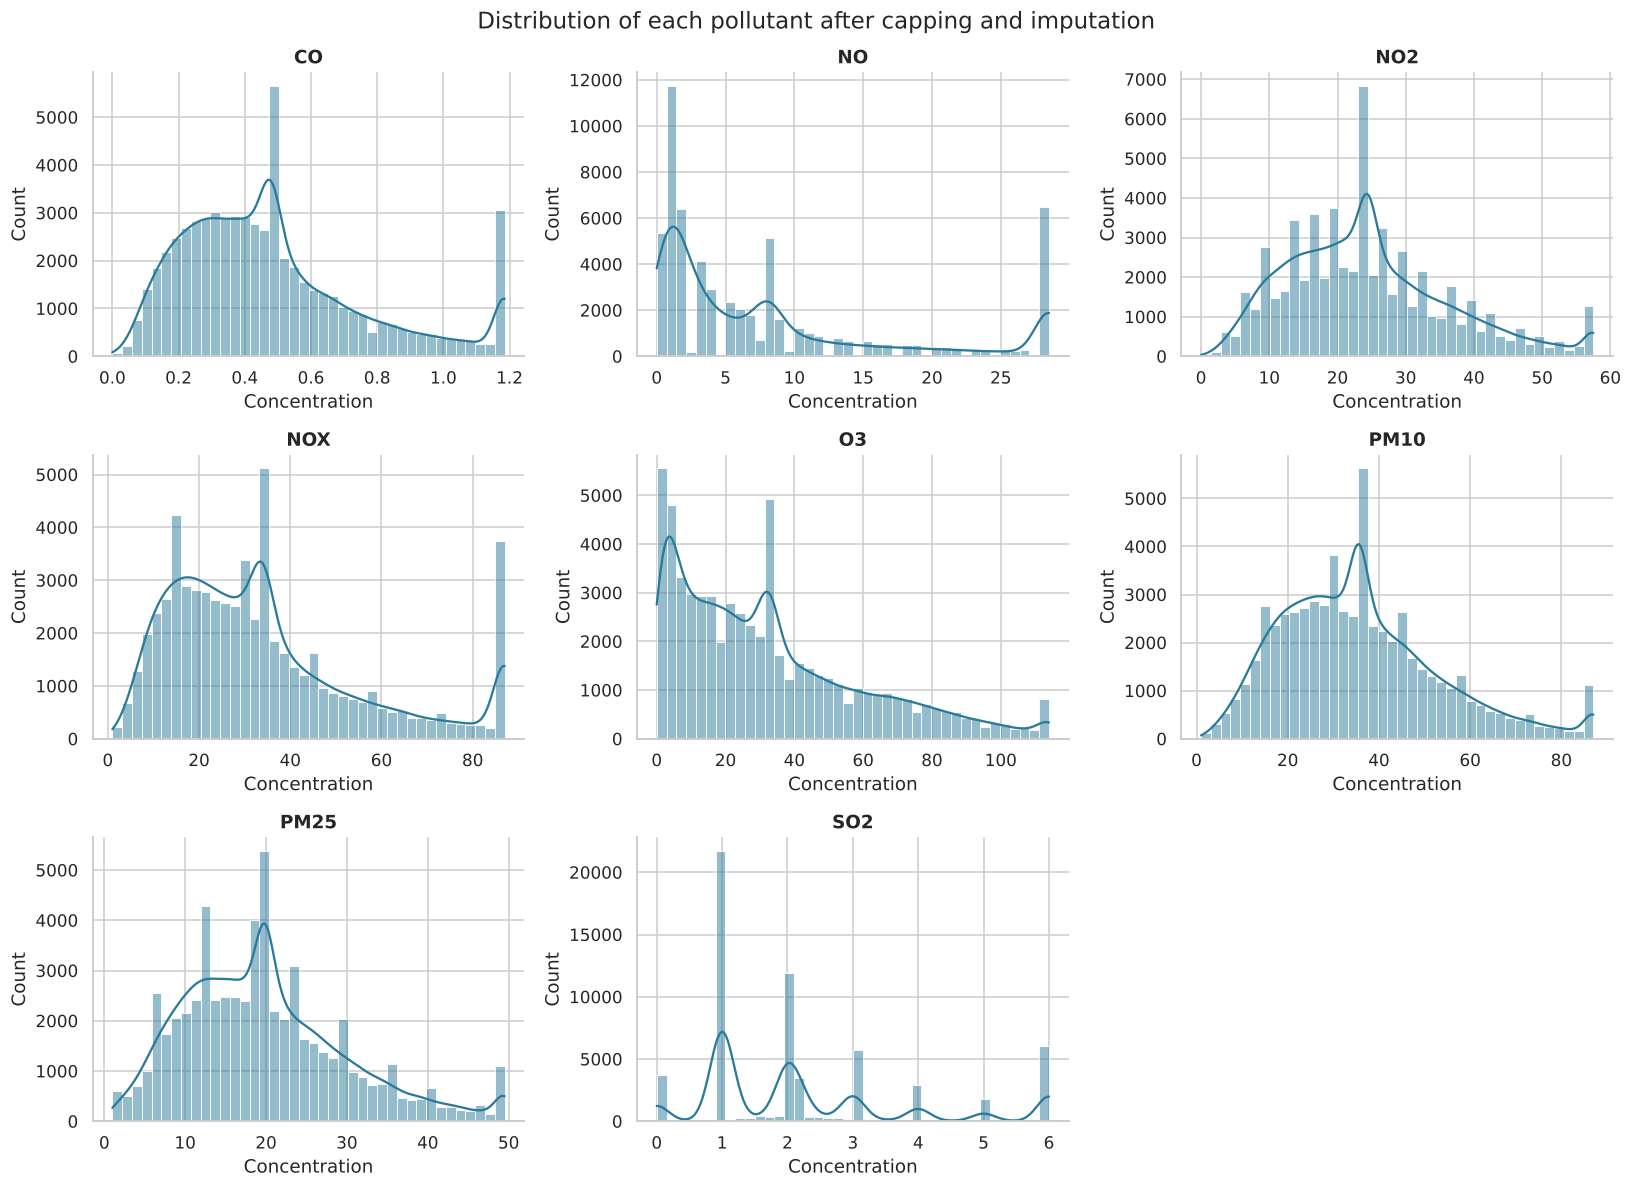

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.flat, POLLUTANTS, strict=False):
    sns.histplot(df[col], kde=True, ax=ax, color="#2A7B9B", edgecolor="white", bins=40)
    ax.set(title=col, xlabel="Concentration", ylabel="Count")
axes.flat[-1].set_visible(False)
fig.suptitle("Distribution of each pollutant after capping and imputation", fontsize=15)
fig.tight_layout()
save_fig(fig, "01_distributions")
plt.show()

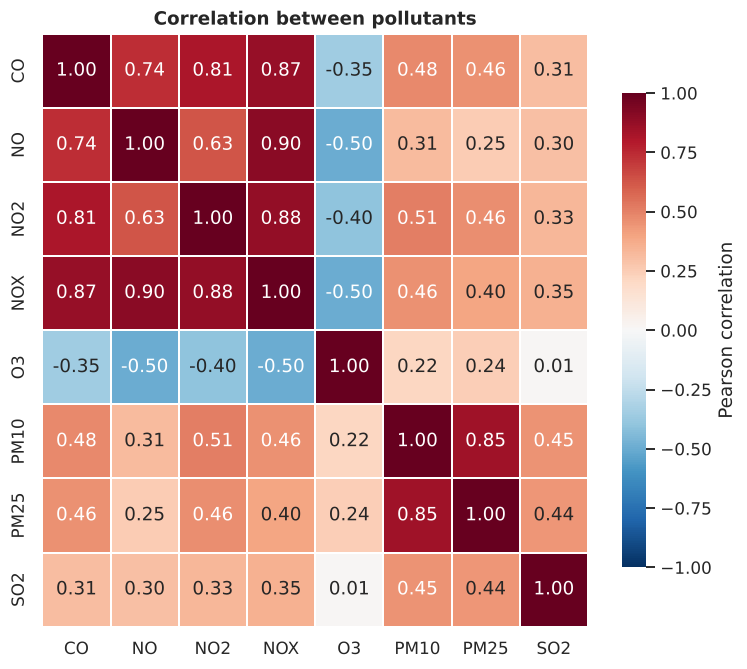

In [11]:
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(
    df[POLLUTANTS].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
    linewidths=1, cbar_kws={"shrink": 0.8, "label": "Pearson correlation"}, ax=ax,
)
ax.set_title("Correlation between pollutants")
save_fig(fig, "01_correlation")
plt.show()

**EDA summary.** The distributions look as expected, and the effect of capping is visible as a
spike at the upper end of several pollutants.

Several pollutants are positively correlated. Those correlations are kept: they are a real
chemical phenomenon and are valuable for clustering. The only variable removed is **NOX**,
because it is the sum of NO and NO2.

Ozone (O3) is negatively correlated with NO and NO2, which matches atmospheric chemistry:
NO consumes ozone near traffic, while ozone builds up in sunny hours away from fresh emissions.

## 4. Choosing the number of clusters

Features are standardized (z-scores) so that every pollutant weighs the same in the distance
calculation, regardless of its units.

In [12]:
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(df[MODEL_FEATURES]), columns=MODEL_FEATURES, index=df.index)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)
print(f"Variance explained by 2 principal components: {pca.explained_variance_ratio_.sum():.1%}")

Variance explained by 2 principal components: 76.0%


K-Means and Gaussian Mixture Models (GMM) are compared with the elbow method (inertia / BIC)
and the silhouette coefficient for k = 2 to 8.

In [13]:
scores = clustering.evaluate_k(X.to_numpy(), range(2, 9))
scores

,kmeans_inertia,kmeans_silhouette,gmm_bic,gmm_silhouette
k,,,,
2,285332.49,0.36,843460.67,2.39e-01
3,225876.65,0.30,797362.89,1.76e-01
4,192072.73,0.25,783053.35,1.31e-01
5,173425.30,0.24,547092.64,-3.44e-02
6,158071.01,0.26,619486.15,2.13e-02
7,142109.41,0.25,531643.51,3.46e-02
8,133629.66,0.22,314804.30,4.07e-03


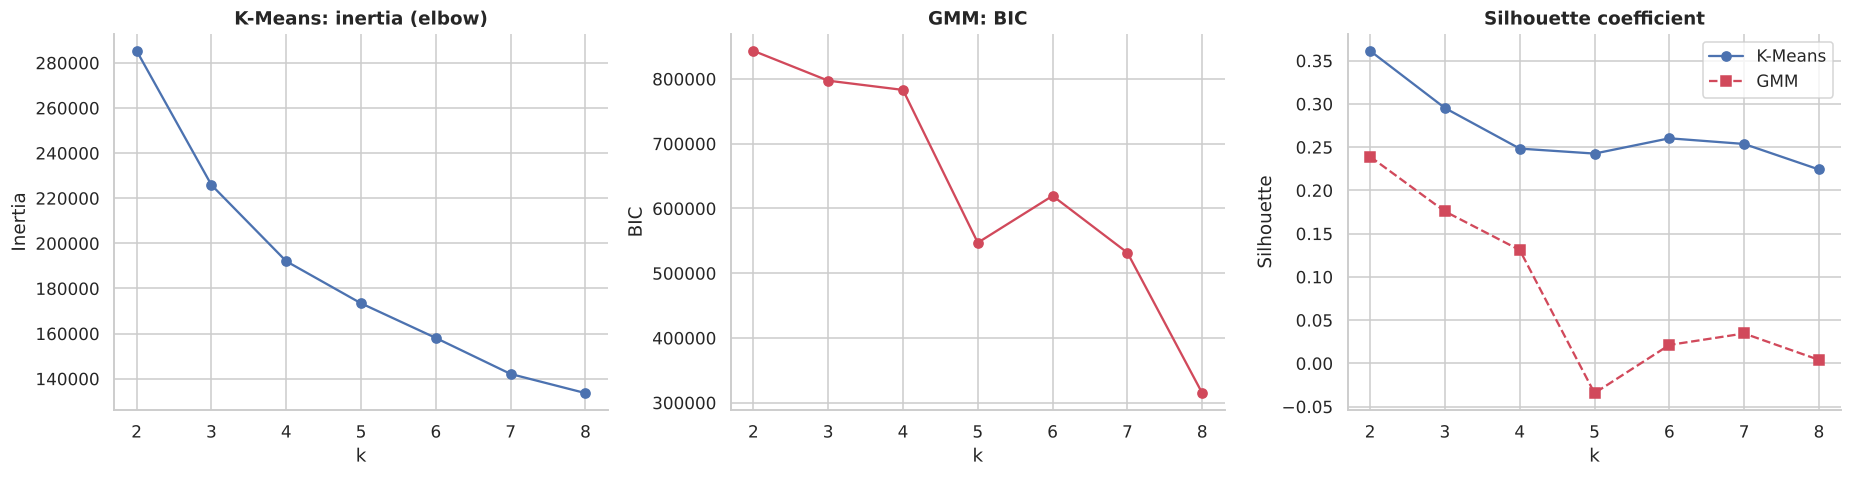

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(scores.index, scores["kmeans_inertia"], "o-")
axes[0].set(title="K-Means: inertia (elbow)", xlabel="k", ylabel="Inertia")
axes[1].plot(scores.index, scores["gmm_bic"], "o-", color="#D1495B")
axes[1].set(title="GMM: BIC", xlabel="k", ylabel="BIC")
axes[2].plot(scores.index, scores["kmeans_silhouette"], "o-", label="K-Means")
axes[2].plot(scores.index, scores["gmm_silhouette"], "s--", label="GMM", color="#D1495B")
axes[2].set(title="Silhouette coefficient", xlabel="k", ylabel="Silhouette")
axes[2].legend()
fig.tight_layout()
save_fig(fig, "01_k_selection")
plt.show()

The metrics favour **k = 2**, which would only separate "clean" from "polluted" air. That is
too coarse for this problem, so more clusters are tried to capture other interactions between
pollutants, accepting slightly lower scores. **K-Means** is chosen over GMM because it scores
better on silhouette, and k = 3, 4 and 5 are compared next.

## 5. K-Means clustering

For each k, the heatmap shows the mean standardized concentration of each pollutant per cluster
(0 = the 2025 average, +1 = one standard deviation above it).

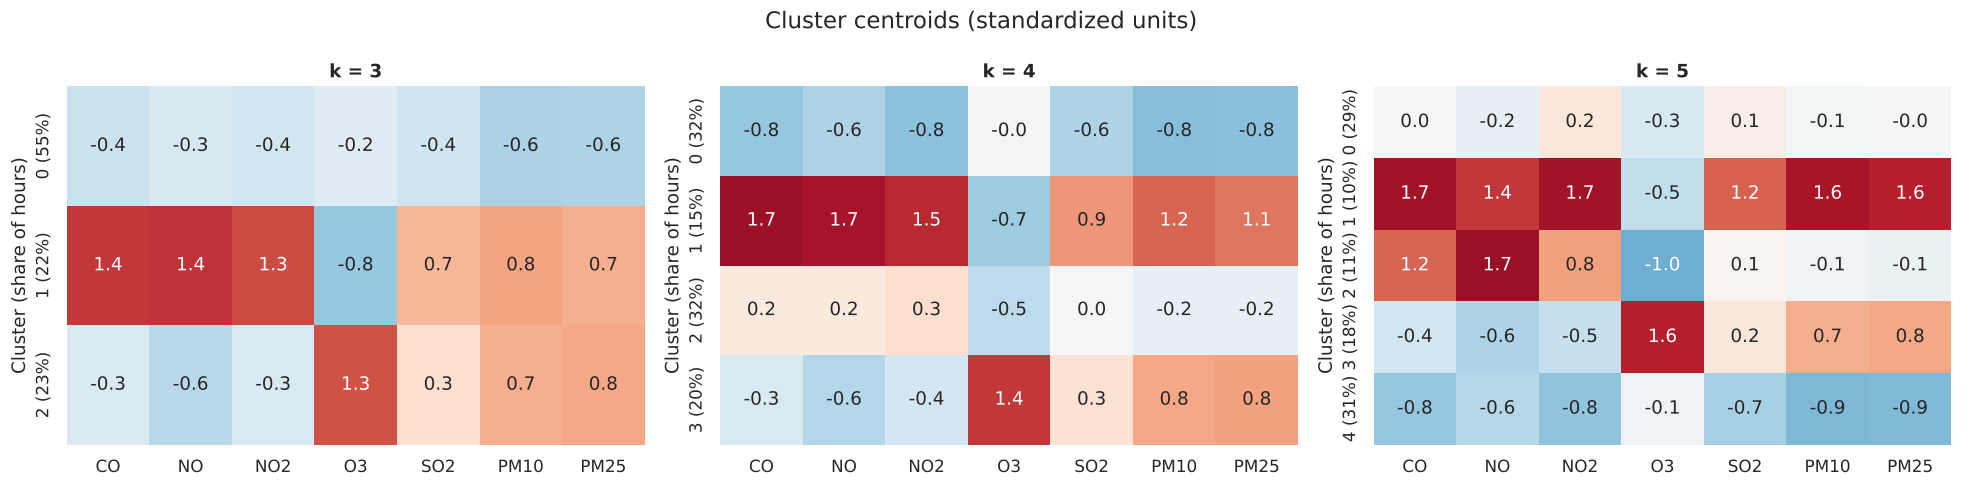

In [15]:
models = {k: clustering.fit_kmeans(X.to_numpy(), k) for k in (3, 4, 5)}

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (k, model) in zip(axes, models.items(), strict=True):
    profile = clustering.cluster_profile(X, model.labels_)
    sns.heatmap(
        profile[MODEL_FEATURES], annot=True, fmt=".1f", cmap="RdBu_r", center=0,
        vmin=-2, vmax=2, cbar=False, ax=ax,
        yticklabels=[f"{c} ({s:.0f}%)" for c, s in profile["share_pct"].items()],
    )
    ax.set(title=f"k = {k}", xlabel="", ylabel="Cluster (share of hours)")
fig.suptitle("Cluster centroids (standardized units)", fontsize=15)
fig.tight_layout()
save_fig(fig, "01_centroids_k3_k4_k5")
plt.show()

**k = 4** gives the most useful segmentation. With 3 clusters, the ozone episodes and the
high-pollution hours are not well separated; with 5, the extra cluster mostly isolates hours
with very high SO2. The rest of the analysis uses **k = 4**.

K-Means numbers its clusters arbitrarily, so the scenarios are named from their centroids
(see `cdmx_air.clustering.name_scenarios`) rather than by hard-coding cluster numbers:

| Scenario | Centroid signature |
|---|---|
| **Clean air** | Below average on every pollutant |
| **Moderate urban** | Slightly above average on traffic pollutants, low ozone |
| **Ozone peak** | Highest ozone |
| **High pollution** | Highest CO, NO, NO2 and particulate matter |

In [16]:
kmeans = models[4]
centroids = pd.DataFrame(kmeans.cluster_centers_, columns=MODEL_FEATURES)
names = clustering.name_scenarios(centroids)

df["scenario"] = pd.Categorical(
    pd.Series(kmeans.labels_, index=df.index).map(names), categories=SCENARIO_ORDER, ordered=True
)
df = add_calendar_features(df)

centroids.rename(index=names).loc[SCENARIO_ORDER]

,CO,NO,NO2,O3,SO2,PM10,PM25
Clean air,-0.78,-0.61,-0.82,-0.04,-0.62,-0.85,-0.84
Moderate urban,0.19,0.20,0.34,-0.52,0.02,-0.18,-0.18
Ozone peak,-0.32,-0.59,-0.37,1.41,0.31,0.77,0.82
High pollution,1.71,1.66,1.51,-0.72,0.89,1.17,1.08


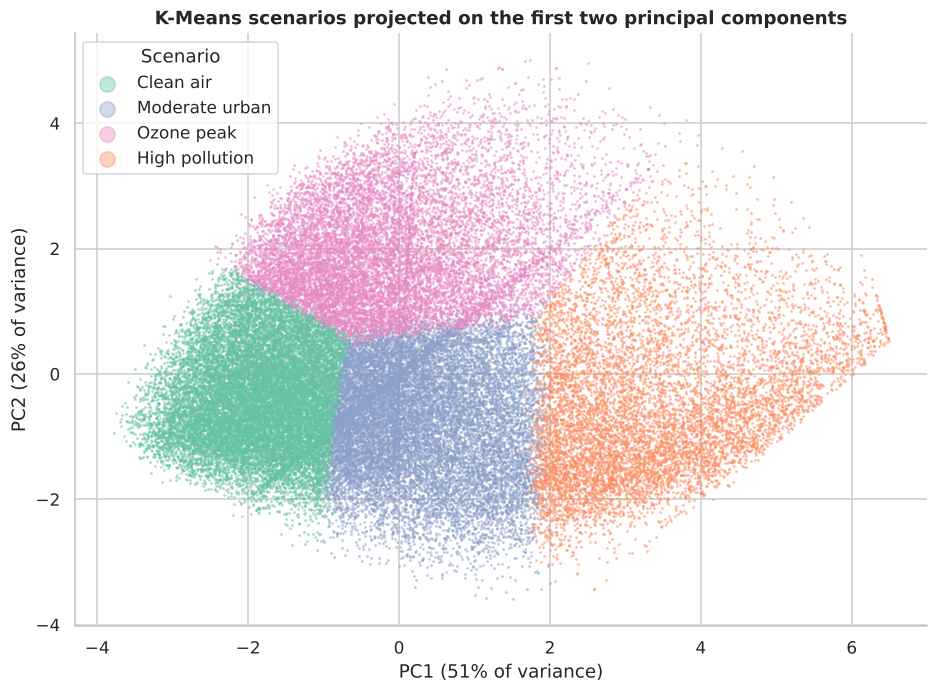

In [17]:
fig, ax = plt.subplots(figsize=(10, 7))
order = np.random.default_rng(42).permutation(len(X_pca))  # avoid one cluster painting over others
for name in SCENARIO_ORDER:
    mask = (df["scenario"] == name).to_numpy()[order]
    ax.scatter(X_pca[order][mask, 0], X_pca[order][mask, 1], s=1, alpha=0.4,
               color=SCENARIO_COLORS[name], label=name, rasterized=True)
ax.set(
    title="K-Means scenarios projected on the first two principal components",
    xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)",
    ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)",
)
ax.legend(markerscale=10, title="Scenario")
save_fig(fig, "01_pca_scenarios")
plt.show()

## 6. Scenario profiling

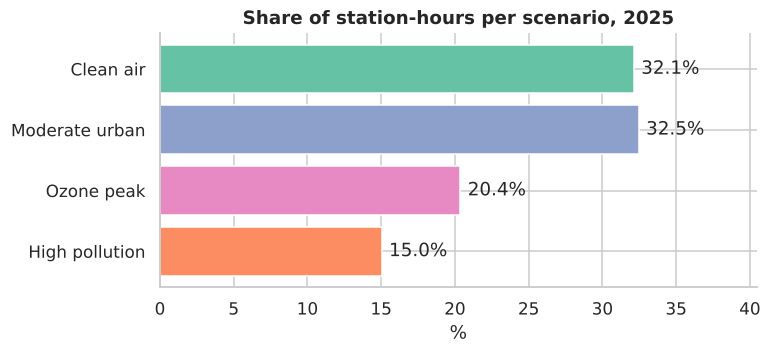

In [18]:
share = df["scenario"].value_counts(normalize=True).loc[SCENARIO_ORDER] * 100
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(share.index, share.values, color=[SCENARIO_COLORS[s] for s in share.index])
for i, v in enumerate(share.values):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center")
ax.invert_yaxis()
ax.set(title="Share of station-hours per scenario, 2025", xlabel="%", xlim=(0, share.max() + 8))
save_fig(fig, "01_scenario_share")
plt.show()

### 6.1 Pollutant distribution per scenario (original units)

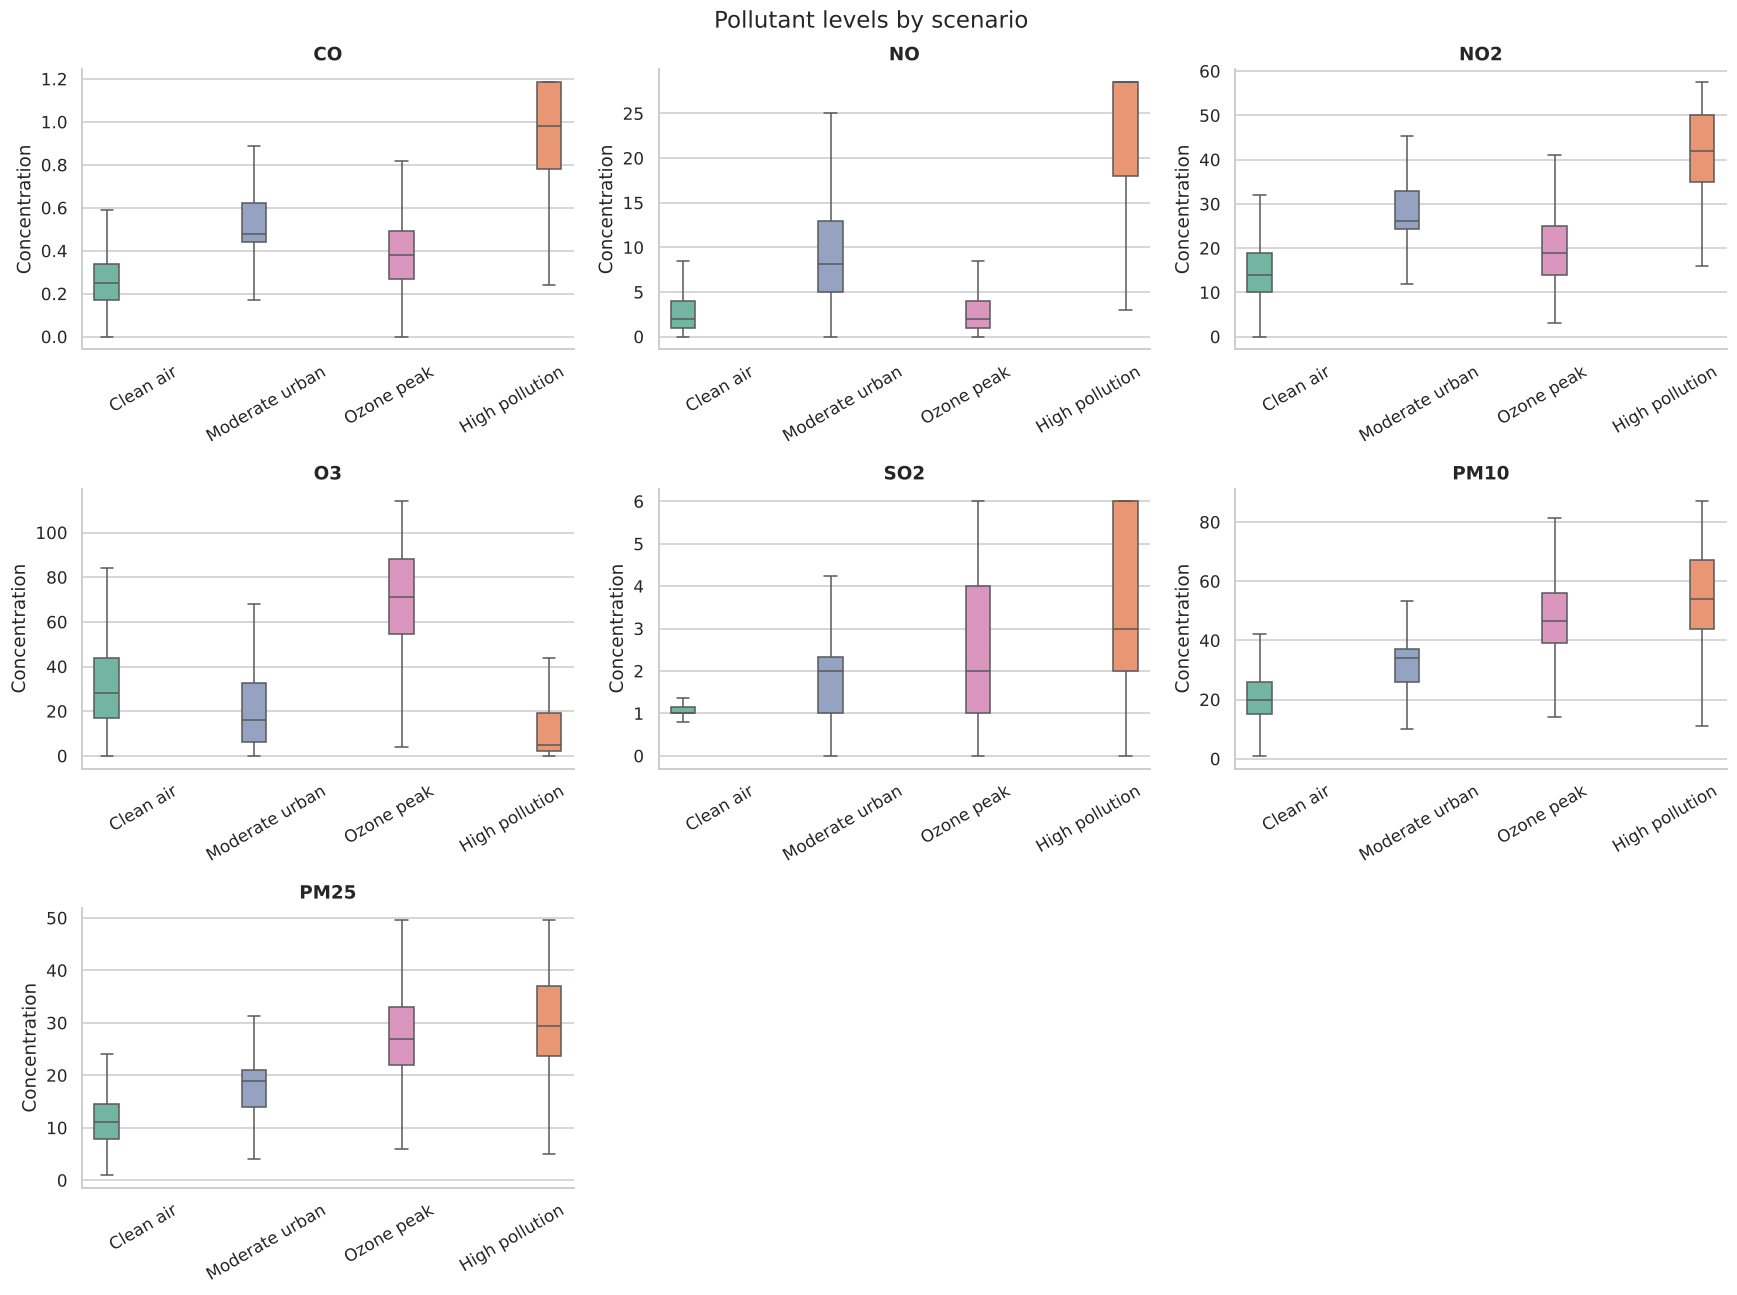

In [19]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.flat, MODEL_FEATURES, strict=False):
    sns.boxplot(data=df, x="scenario", y=col, hue="scenario", palette=SCENARIO_COLORS,
                showfliers=False, legend=False, ax=ax)
    ax.set(title=col, xlabel="", ylabel="Concentration")
    ax.tick_params(axis="x", rotation=30)
for ax in axes.flat[len(MODEL_FEATURES):]:
    ax.set_visible(False)
fig.suptitle("Pollutant levels by scenario", fontsize=15)
fig.tight_layout()
save_fig(fig, "01_boxplots_by_scenario")
plt.show()

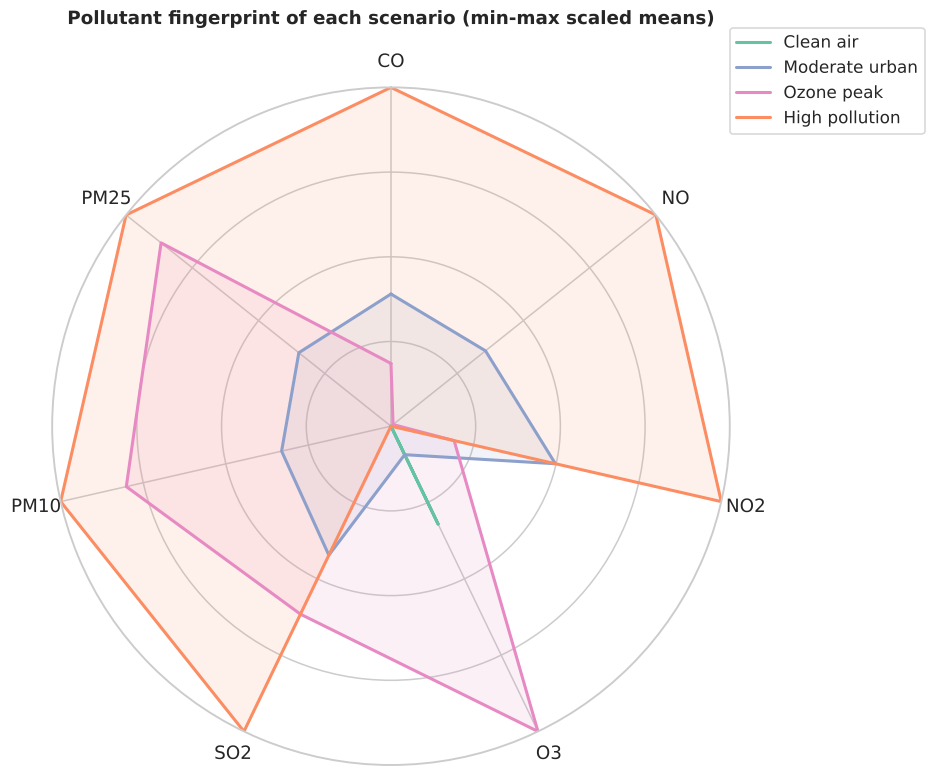

In [20]:
means = df.groupby("scenario", observed=True)[MODEL_FEATURES].mean()
radar = pd.DataFrame(MinMaxScaler().fit_transform(means), index=means.index, columns=MODEL_FEATURES)

angles = np.linspace(0, 2 * np.pi, len(MODEL_FEATURES), endpoint=False).tolist()
angles += angles[:1]
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"polar": True})
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
for name, row in radar.iterrows():
    values = row.tolist() + row.tolist()[:1]
    ax.plot(angles, values, linewidth=2, label=name, color=SCENARIO_COLORS[name])
    ax.fill(angles, values, alpha=0.12, color=SCENARIO_COLORS[name])
ax.set_xticks(angles[:-1], MODEL_FEATURES, fontsize=12)
ax.set_yticks([0.25, 0.5, 0.75], ["", "", ""])
ax.set_ylim(0, 1)
ax.set_title("Pollutant fingerprint of each scenario (min-max scaled means)", y=1.08)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
save_fig(fig, "01_radar")
plt.show()

### 6.2 Daily cycle

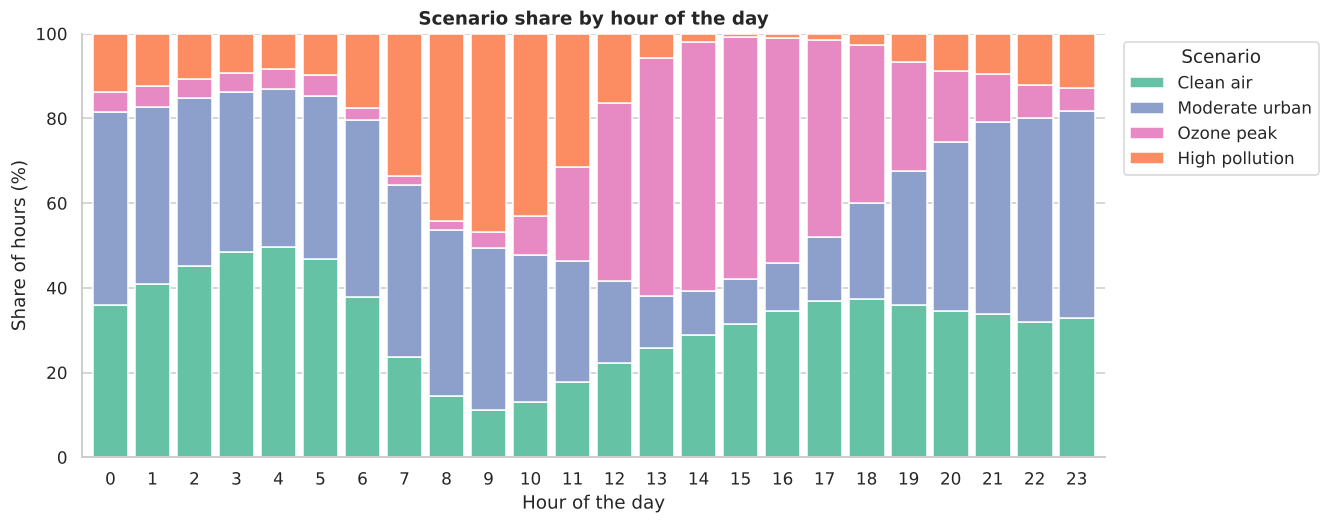

In [21]:
by_hour = pd.crosstab(df["hour"], df["scenario"], normalize="index") * 100
fig = stacked_share(by_hour, "Scenario share by hour of the day", "Hour of the day")
save_fig(fig, "01_share_by_hour")
plt.show()

### 6.3 Weekly cycle

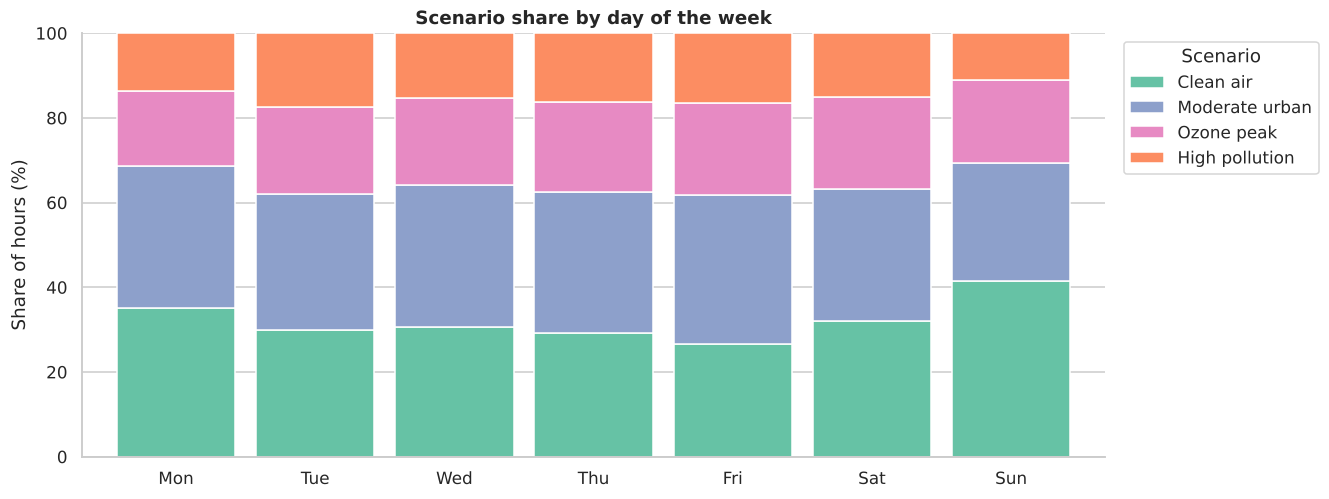

In [22]:
by_weekday = pd.crosstab(df["weekday"], df["scenario"], normalize="index") * 100
by_weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig = stacked_share(by_weekday, "Scenario share by day of the week", "")
save_fig(fig, "01_share_by_weekday")
plt.show()

### 6.4 Seasonality

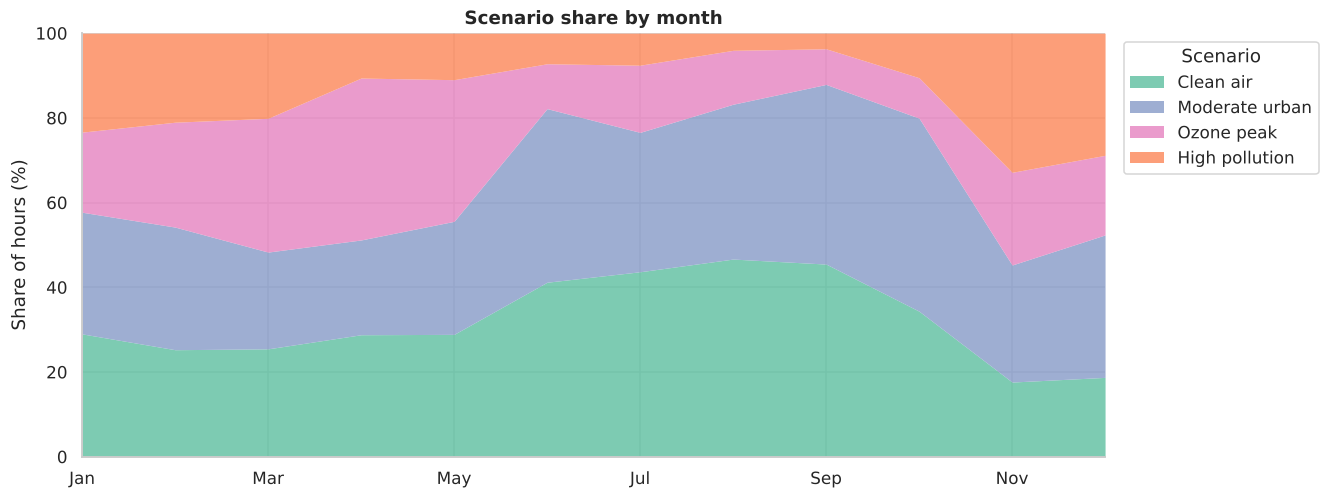

In [23]:
by_month = pd.crosstab(df["month"], df["scenario"], normalize="index") * 100
by_month.index = MONTHS
fig = stacked_share(by_month, "Scenario share by month", "", kind="area")
save_fig(fig, "01_share_by_month")
plt.show()

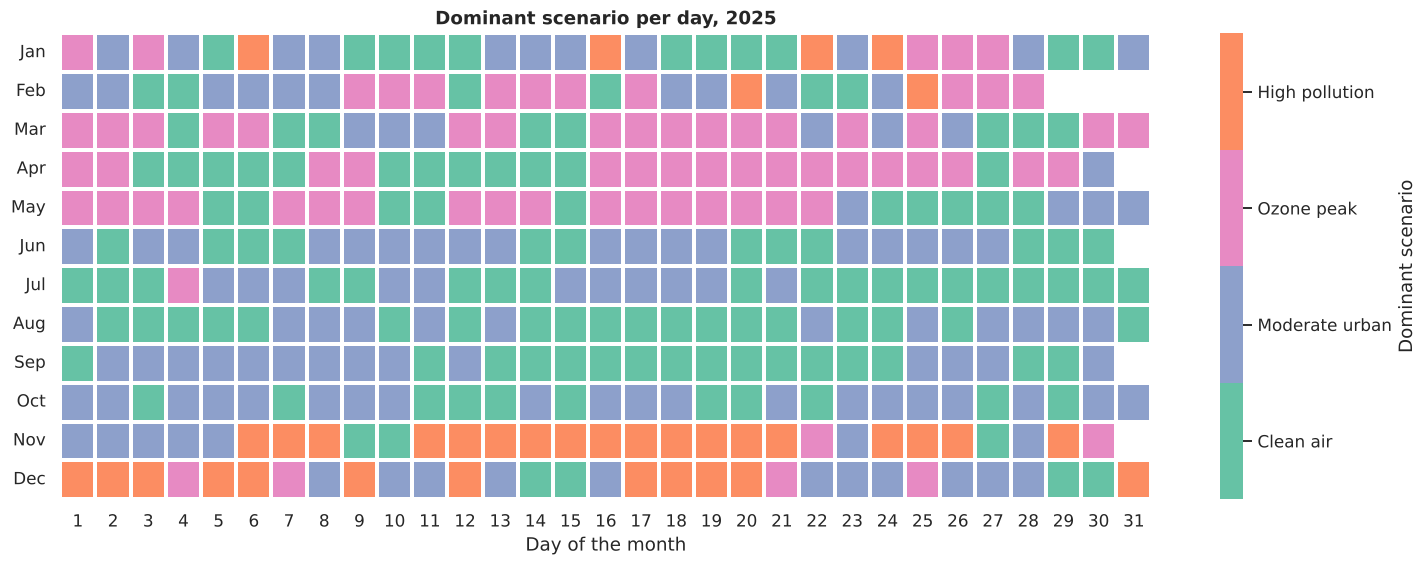

In [24]:
daily = df.assign(day=(df["datetime"] - pd.Timedelta(hours=1)).dt.normalize())
daily = daily[daily["day"].dt.year == 2025]
dominant = daily.groupby("day")["scenario"].agg(lambda s: s.mode().iloc[0]).cat.codes
calendar = (
    dominant.rename("code").reset_index()
    .assign(month=lambda d: d["day"].dt.month, dom=lambda d: d["day"].dt.day)
    .pivot(index="month", columns="dom", values="code")
)
calendar.index = MONTHS

fig, ax = plt.subplots(figsize=(16, 5.5))
sns.heatmap(calendar, cmap=[SCENARIO_COLORS[s] for s in SCENARIO_ORDER], vmin=-0.5, vmax=3.5,
            linewidths=1.5, linecolor="white", ax=ax,
            cbar_kws={"ticks": range(4), "label": "Dominant scenario"})
ax.collections[0].colorbar.set_ticklabels(SCENARIO_ORDER)
ax.set(title="Dominant scenario per day, 2025", xlabel="Day of the month", ylabel="")
ax.grid(False)
ax.tick_params(axis="y", rotation=0)
save_fig(fig, "01_calendar")
plt.show()

### 6.5 Differences between stations

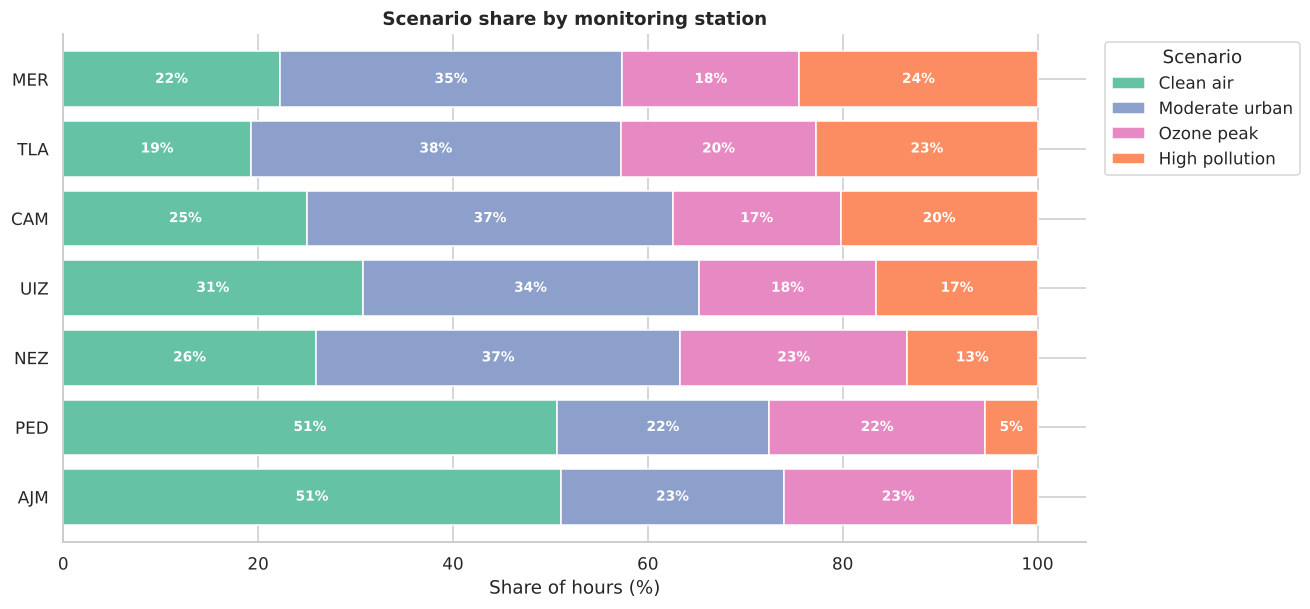

In [25]:
by_station = pd.crosstab(df["station"], df["scenario"], normalize="index") * 100
by_station = by_station.sort_values("High pollution")
fig, ax = plt.subplots(figsize=(12, 6))
by_station.plot(kind="barh", stacked=True, width=0.8, edgecolor="white", ax=ax,
                color=[SCENARIO_COLORS[c] for c in by_station.columns])
for container in ax.containers:
    ax.bar_label(container, labels=[f"{w:.0f}%" if w > 4 else "" for w in container.datavalues],
                 label_type="center", color="white", weight="bold", fontsize=9)
ax.set(title="Scenario share by monitoring station", xlabel="Share of hours (%)", ylabel="")
ax.legend(title="Scenario", bbox_to_anchor=(1.01, 1), loc="upper left")
save_fig(fig, "01_share_by_station")
plt.show()

### 6.6 Hour-to-hour transitions

Probability of moving from one scenario to another in the next hour, computed within each
station's own time series.

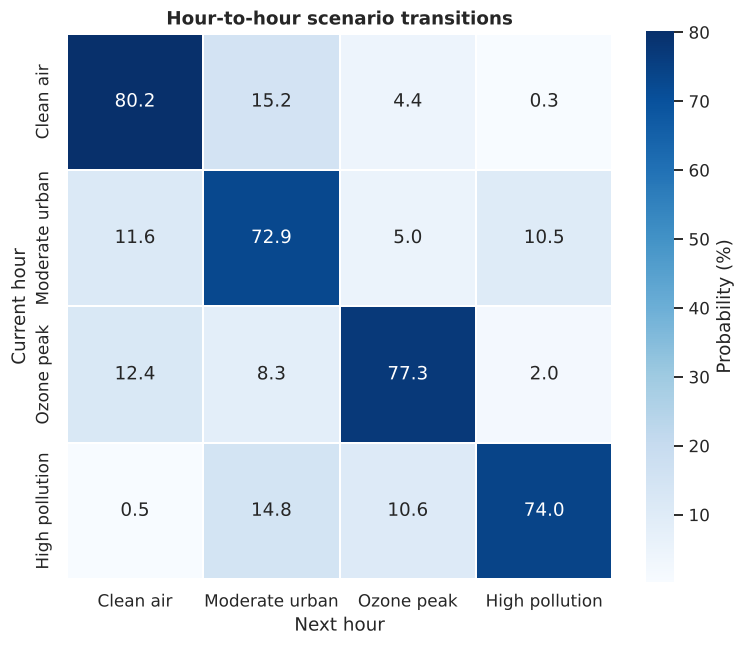

On average, the scenario stays the same in the next hour 76.1% of the time.


In [26]:
transitions = clustering.transition_matrix(df).loc[SCENARIO_ORDER, SCENARIO_ORDER]
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(transitions, annot=True, fmt=".1f", cmap="Blues", square=True, linewidths=1,
            cbar_kws={"label": "Probability (%)"}, ax=ax)
ax.set(title="Hour-to-hour scenario transitions", xlabel="Next hour", ylabel="Current hour")
save_fig(fig, "01_transition_matrix")
plt.show()

persistence = np.diag(transitions).mean()
print(f"On average, the scenario stays the same in the next hour {persistence:.1f}% of the time.")

## 7. Conclusions

* Four scenarios describe 2025 well: **Clean air**, **Moderate urban**, **Ozone peak** and
  **High pollution**. Ozone behaves differently from the traffic-related pollutants (CO, NO,
  NO2), which is why it forms its own scenario.
* The **daily cycle** is the strongest pattern. High pollution peaks during the morning rush
  (about 45% of hours between 8 and 10 a.m.), ozone peaks in the early afternoon with sunlight
  (close to 60% of hours between 1 and 3 p.m.), and clean air is most common before dawn.
* **Seasonality.** Ozone episodes concentrate in the warm, dry months (March to May). High
  pollution is most frequent in November and December, and the rainy season (June to September)
  is the cleanest part of the year.
* **Weekly cycle.** Sundays have the largest share of clean air (41%) and the smallest share of
  high pollution, consistent with lower traffic.
* **Stations differ.** AJM and PED (south-west of the city) spend about half of their hours in
  clean air and less than 5% in high pollution, while MER and TLA spend close to a quarter of
  their hours in high pollution.
* **Scenarios are persistent** hour to hour: each one stays the same in the next hour 73–80% of
  the time. That makes forecasting the next hour feasible, and it also sets a strong baseline
  that any forecasting model has to beat. This is the starting point of the second notebook.

**Limitations.** The clustering uses a single year and only seven stations, and meteorological
variables (temperature, wind, radiation) are not included. The scenario names describe pollutant
patterns; they are not the official air-quality index categories.